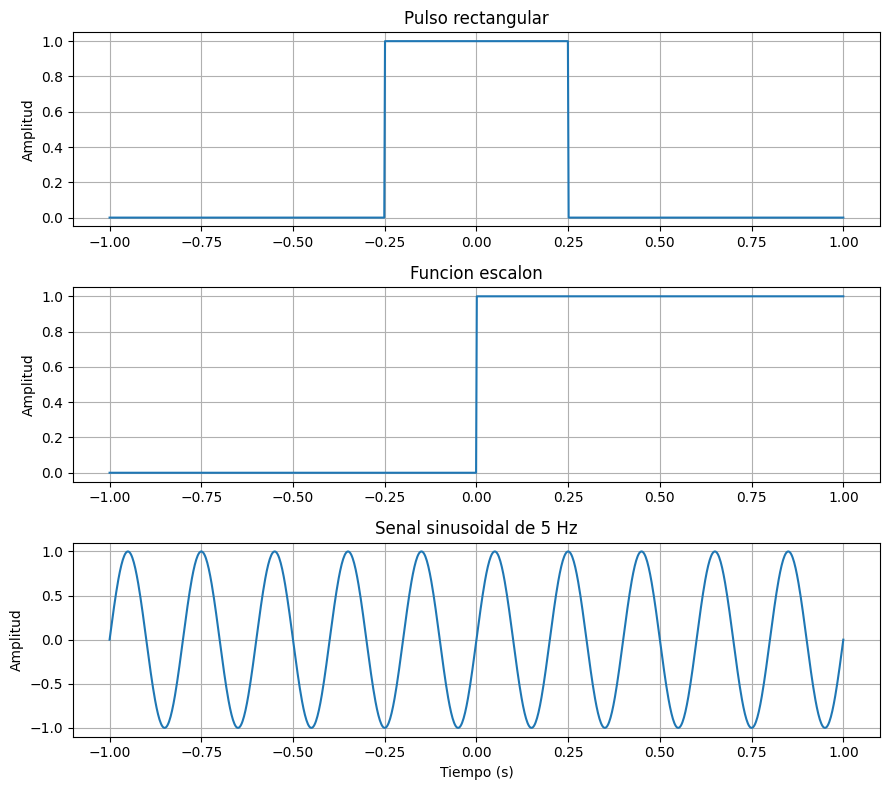

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Definir el tiempo
t = np.linspace(-1, 1, 1000)

# 1. Pulso rectangular
pulso = np.where(np.abs(t) <= 0.25, 1.0, 0.0)

# 2. Funcion escalon
escalon = np.where(t >= 0, 1.0, 0.0)

# 3. Senal sinusoidal
frecuencia = 5
senoidal = np.sin(2 * np.pi * frecuencia * t)

# Graficar las tres senales
fig, ax = plt.subplots(3, 1, figsize=(9, 8))

ax[0].plot(t, pulso)
ax[0].set_title("Pulso rectangular")
ax[0].set_ylabel("Amplitud")
ax[0].grid(True)

ax[1].plot(t, escalon)
ax[1].set_title("Funcion escalon")
ax[1].set_ylabel("Amplitud")
ax[1].grid(True)

ax[2].plot(t, senoidal)
ax[2].set_title("Senal sinusoidal de 5 Hz")
ax[2].set_xlabel("Tiempo (s)")
ax[2].set_ylabel("Amplitud")
ax[2].grid(True)

plt.tight_layout()
plt.show()


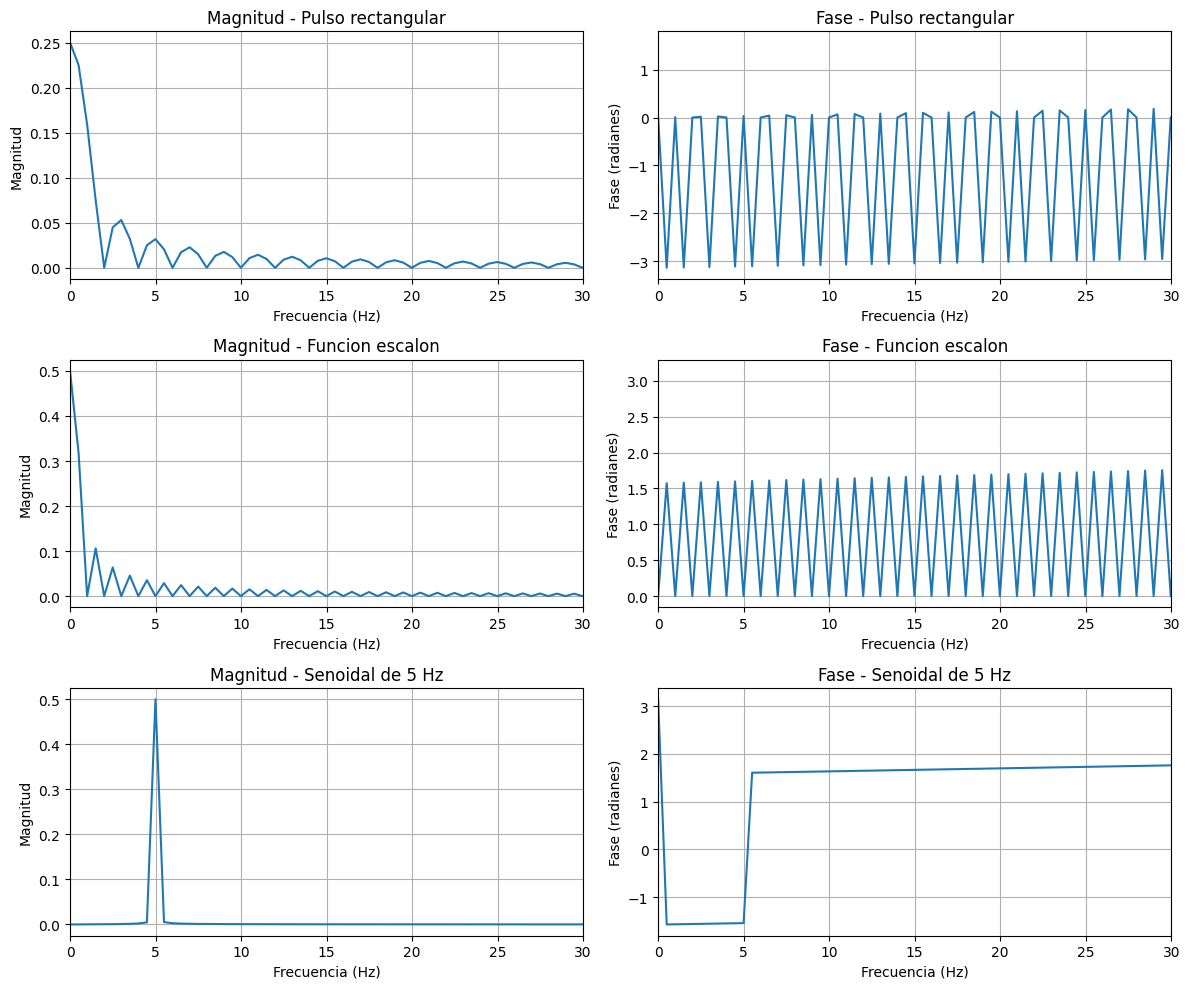

In [5]:

# Transformada de Fourier de las tres señales

# Frecuencia de muestreo
dt = t[1] - t[0]
fs = 1 / dt
N = len(t)

# Eje de frecuencias
frecuencias = np.fft.fftfreq(N, d=dt)
mascara = frecuencias >= 0
f = frecuencias[mascara]

senales = {
    "Pulso rectangular": pulso,
    "Funcion escalon": escalon,
    "Senoidal de 5 Hz": senoidal
}

fig, ax = plt.subplots(3, 2, figsize=(12, 10))

for i, (nombre, x) in enumerate(senales.items()):
    X = np.fft.fft(x)

    # Magnitud normalizada y fase
    magnitud = np.abs(X) / N
    fase = np.angle(X)

    ax[i, 0].plot(f, magnitud[mascara])
    ax[i, 0].set_title(f"Magnitud - {nombre}")
    ax[i, 0].set_xlabel("Frecuencia (Hz)")
    ax[i, 0].set_ylabel("Magnitud")
    ax[i, 0].set_xlim(0, 30)
    ax[i, 0].grid(True)

    ax[i, 1].plot(f, fase[mascara])
    ax[i, 1].set_title(f"Fase - {nombre}")
    ax[i, 1].set_xlabel("Frecuencia (Hz)")
    ax[i, 1].set_ylabel("Fase (radianes)")
    ax[i, 1].set_xlim(0, 30)
    ax[i, 1].grid(True)

plt.tight_layout()
plt.show()


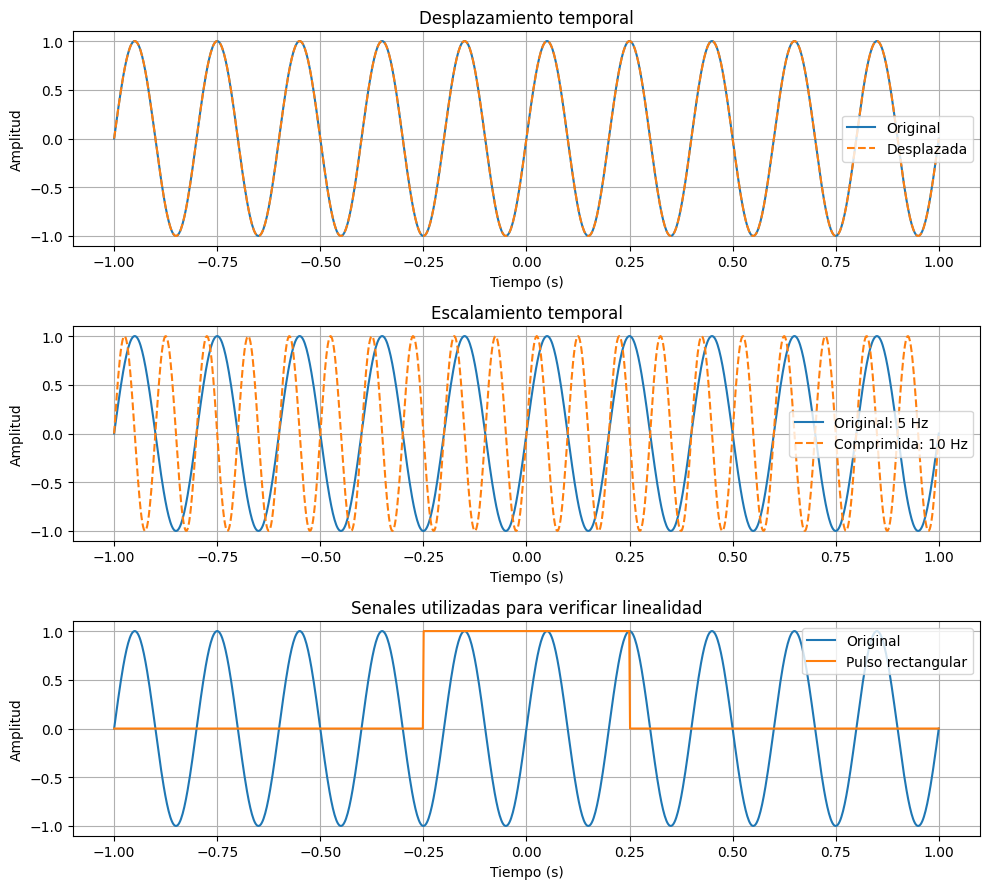

Error maximo de linealidad: 2.31335954426011e-13


In [6]:

# Comprobacion de propiedades de la Transformada de Fourier

# Usaremos la senal sinusoidal generada anteriormente
x = senoidal.copy()

# 1. Linealidad: FFT(a*x + b*y) = a*FFT(x) + b*FFT(y)
y = pulso.copy()
a, b = 2, 3

izquierda = np.fft.fft(a*x + b*y)
derecha = a*np.fft.fft(x) + b*np.fft.fft(y)

error_linealidad = np.max(np.abs(izquierda - derecha))

# 2. Desplazamiento temporal de la senal
desplazamiento = 0.2
x_desplazada = np.sin(2*np.pi*frecuencia*(t - desplazamiento))

# 3. Escalamiento temporal: x(2t)
x_comprimida = np.sin(2*np.pi*frecuencia*2*t)

fig, ax = plt.subplots(3, 1, figsize=(10, 9))

ax[0].plot(t, x, label="Original")
ax[0].plot(t, x_desplazada, "--", label="Desplazada")
ax[0].set_title("Desplazamiento temporal")
ax[0].set_xlabel("Tiempo (s)")
ax[0].set_ylabel("Amplitud")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(t, x, label="Original: 5 Hz")
ax[1].plot(t, x_comprimida, "--", label="Comprimida: 10 Hz")
ax[1].set_title("Escalamiento temporal")
ax[1].set_xlabel("Tiempo (s)")
ax[1].set_ylabel("Amplitud")
ax[1].legend()
ax[1].grid(True)

ax[2].plot(t, x, label="Original")
ax[2].plot(t, y, label="Pulso rectangular")
ax[2].set_title("Senales utilizadas para verificar linealidad")
ax[2].set_xlabel("Tiempo (s)")
ax[2].set_ylabel("Amplitud")
ax[2].legend()
ax[2].grid(True)

plt.tight_layout()
plt.show()

print("Error maximo de linealidad:", error_linealidad)
